# Results: Cross-fitted Text Experts vs. MulTaBench Joint TAR

This notebook compares our method (`cte_depth_top3_attn`: cross-fitted text experts, a linear probe, depth probes and
an attention probe on a frozen e5-small-v2 encoder) with the baselines published by
[MulTaBench](https://github.com/alanarazi7/MulTaBench). "Depth-probe version" (`cte_depth_top3`) is the same method
without the attention probe; some checks (36 further datasets, other seeds, cost) were run with it.

- **Datasets:** the 20 MulTaBench text-tabular datasets, the benchmark's 5 folds (test = 10% of rows, at most 2,000).
- **Learners:** CatBoost, LightGBM, TabM, TabPFN-v2, TabPFN-2.5, each with upstream default settings.
- **Metric:** AUROC for classification (macro one-vs-rest for multiclass), R² for regression, exactly as upstream.
- **Baselines:** the leaderboard scores of the same learner, dataset and fold. **Joint TAR** fine-tunes e5 on the
  target; **Joint Frozen** uses e5 as is. TabPFN cannot run Spotify Genres (114 classes) and Wine Review (30
  classes), so MulTaBench has no TabPFN baseline there (18 datasets).

Inputs: `results/*.csv` (built by `scripts/make_results.py` from `reports/tables/fold_scores.csv`) and `reports/`.

In [1]:
import json
import os
from os.path import exists, join

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from scipy.stats import spearmanr, wilcoxon

ROOT = ".." if exists("../results") else "."
R = lambda *p: join(ROOT, *p)
FIG = R("results", "figures")
os.makedirs(FIG, exist_ok=True)

folds = pd.read_csv(R("results", "scores_per_fold.csv"))
per_ds = pd.read_csv(R("results", "scores_per_dataset.csv"))
summary = pd.read_csv(R("results", "summary.csv")).set_index("learner")
LEARNERS = ["CatBoost", "LightGBM", "TabM", "TabPFN-v2", "TabPFN-2.5"]
NAME = lambda d: d.split("_TEXT_", 1)[1].replace("_", " ").title().replace("Us ", "US ")
TASK = {"BIN": "binary", "MUL": "multiclass", "REG": "regression"}
per_ds["name"] = per_ds.dataset.map(NAME)
per_ds["task_type"] = per_ds.dataset.str[:3].map(TASK)
C_OURS, C_TAR, C_FROZEN = "#d95f02", "#1f78b4", "#b0b0b0"
plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False})
pd.set_option("display.precision", 4)
print(f"{len(folds)} (learner, dataset, fold) scores; {per_ds.dataset.nunique()} datasets")

480 (learner, dataset, fold) scores; 20 datasets


## 1. Headline: our method vs. Joint TAR, with the learner held fixed

Left: each pair of bars is one learner, the mean over datasets of the leaderboard's Joint TAR score and of our score
on the same folds (the axis starts at 0.70, so the bars exaggerate the differences). Right: the same gains on their own
scale, with 95% bootstrap intervals over datasets. Means mix AUROC and R², as the benchmark's own summaries do.

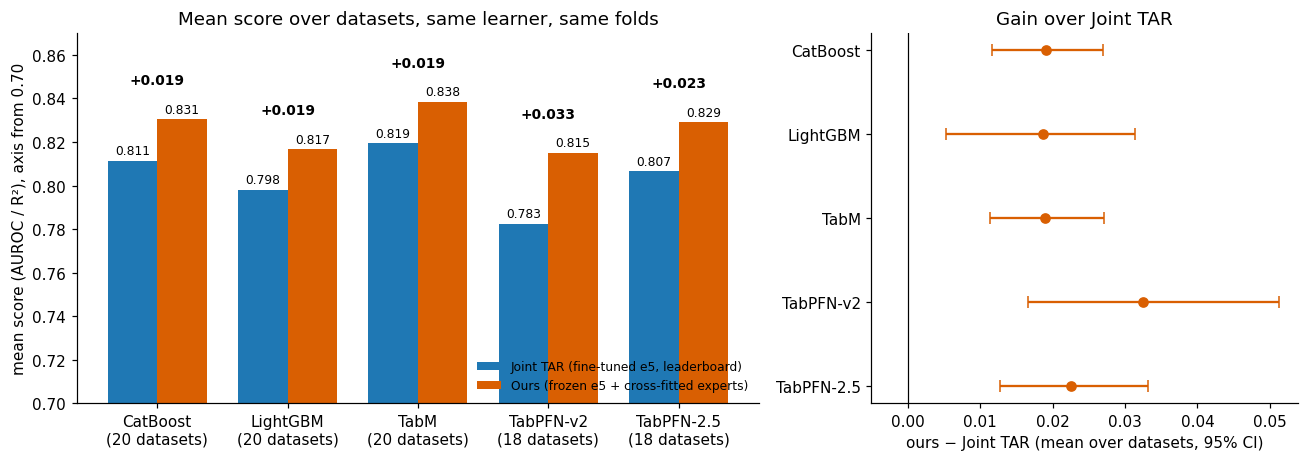

In [2]:
x = np.arange(len(LEARNERS)); w = 0.38
s = summary.loc[LEARNERS]
fig, (ax, ax2) = plt.subplots(1, 2, figsize=(12, 4.3), gridspec_kw={"width_ratios": [1.6, 1]})
ax.bar(x - w / 2, s.joint_tar, w, color=C_TAR, label="Joint TAR (fine-tuned e5, leaderboard)")
ax.bar(x + w / 2, s.ours, w, color=C_OURS, label="Ours (frozen e5 + cross-fitted experts)")
for i, (t, o) in enumerate(zip(s.joint_tar, s.ours)):
    ax.text(i - w / 2, t + 0.003, f"{t:.3f}", ha="center", fontsize=8)
    ax.text(i + w / 2, o + 0.003, f"{o:.3f}", ha="center", fontsize=8)
    ax.text(i, max(t, o) + 0.016, f"+{o - t:.3f}", ha="center", fontsize=9, fontweight="bold")
ax.set_xticks(x, [f"{l}\n({int(n)} datasets)" for l, n in zip(LEARNERS, s.datasets)])
ax.set_ylim(0.70, 0.87); ax.set_ylabel("mean score (AUROC / R²), axis from 0.70")
ax.set_title("Mean score over datasets, same learner, same folds")
ax.legend(loc="lower right", fontsize=8, frameon=False)
ax2.errorbar(s.mean_gain, x, xerr=[s.mean_gain - s.ci95_low, s.ci95_high - s.mean_gain], fmt="o", color=C_OURS, capsize=4)
ax2.axvline(0, color="k", lw=0.8); ax2.set_yticks(x, LEARNERS); ax2.invert_yaxis(); ax2.set_xlim(left=-0.005)
ax2.set_xlabel("ours − Joint TAR (mean over datasets, 95% CI)"); ax2.set_title("Gain over Joint TAR")
fig.tight_layout(); fig.savefig(join(FIG, "fig1_mean_by_learner.png"), dpi=200); plt.show()

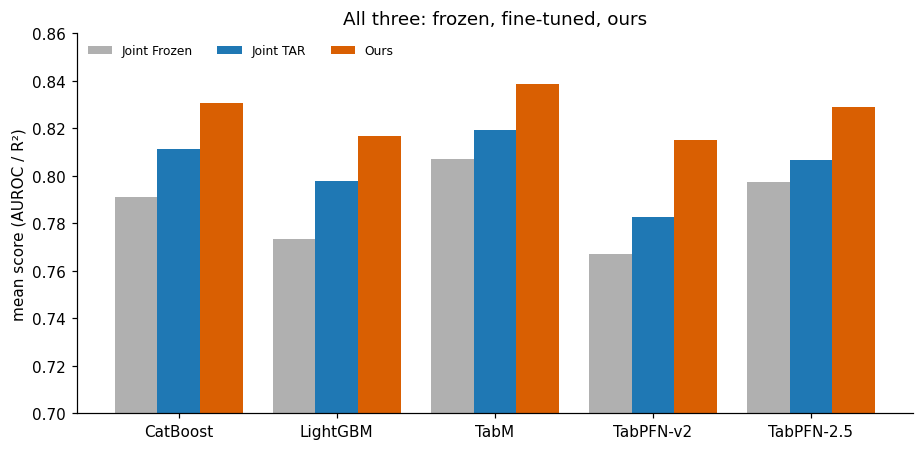

Joint TAR - Joint Frozen (what fine-tuning buys): {'CatBoost': 0.0204, 'LightGBM': 0.0246, 'TabM': 0.0122, 'TabPFN-v2': 0.0155, 'TabPFN-2.5': 0.0094}
Ours - Joint TAR: {'CatBoost': 0.0191, 'LightGBM': 0.0187, 'TabM': 0.019, 'TabPFN-v2': 0.0325, 'TabPFN-2.5': 0.0226}
(Ours - Frozen) / (TAR - Frozen), our gain over Frozen as a multiple of fine-tuning's: {'CatBoost': 1.94, 'LightGBM': 1.76, 'TabM': 2.55, 'TabPFN-v2': 3.09, 'TabPFN-2.5': 3.4}


In [3]:
fig, ax = plt.subplots(figsize=(8.5, 4.2)); w = 0.27
ax.bar(x - w, s.joint_frozen, w, color=C_FROZEN, label="Joint Frozen")
ax.bar(x, s.joint_tar, w, color=C_TAR, label="Joint TAR")
ax.bar(x + w, s.ours, w, color=C_OURS, label="Ours")
ax.set_xticks(x, LEARNERS); ax.set_ylim(0.70, 0.86); ax.set_ylabel("mean score (AUROC / R²)")
ax.set_title("All three: frozen, fine-tuned, ours")
ax.legend(fontsize=8, frameon=False, ncol=3, loc="upper left")
fig.tight_layout(); fig.savefig(join(FIG, "fig1b_frozen_tar_ours.png"), dpi=200); plt.show()
gap = (s.joint_tar - s.joint_frozen)
print("Joint TAR - Joint Frozen (what fine-tuning buys):", gap.round(4).to_dict())
print("Ours - Joint TAR:", (s.ours - s.joint_tar).round(4).to_dict())
print("(Ours - Frozen) / (TAR - Frozen), our gain over Frozen as a multiple of fine-tuning's:",
      ((s.ours - s.joint_frozen) / gap).round(2).to_dict())

## 2. Statistical tests

For each learner: one number per dataset, our score minus Joint TAR averaged over the 5 folds, then a two-sided
Wilcoxon signed-rank test over datasets (do the gains lean consistently positive, or could the signs be chance?).
Each test was written down before its run. **Holm (24)** corrects across the 24 pre-registered benchmark comparisons
of the project, the strictest reading (over the five final comparisons alone, the pre-registered reading of the final
claim, all five pass). The correlations and other analyses in this notebook are exploratory. The 95% interval is a bootstrap over datasets.

In [4]:
p18 = json.load(open(R("reports", "p18", "p18_report.json")))
holm = p18["holm_all_preregistered"]
SHORT = {"CatBoost": "catboost", "LightGBM": "lgbm", "TabM": "tabm", "TabPFN-v2": "tabpfnv2", "TabPFN-2.5": "tabpfnv2p5"}
t = s[["datasets", "joint_tar", "ours", "mean_gain", "median_gain", "ci95_low", "ci95_high", "wins", "wilcoxon_p"]].copy()
t["holm_24"] = [holm["C13_" + SHORT[l]] for l in t.index]
t["passes (p < 0.05)"] = t.wilcoxon_p < 0.05
t["passes Holm (24)"] = t.holm_24 < 0.05
t

,datasets,joint_tar,ours,mean_gain,median_gain,ci95_low,ci95_high,wins,wilcoxon_p,holm_24,passes (p < 0.05),passes Holm (24)
learner,,,,,,,,,,,,
CatBoost,20,0.8114,0.8305,0.0191,0.0169,0.0117,0.0270,18,1.9000e-05,0.0004,True,True
LightGBM,20,0.7980,0.8167,0.0187,0.0136,0.0053,0.0314,16,7.2960e-03,0.0948,True,False
TabM,20,0.8195,0.8385,0.0190,0.0110,0.0113,0.0272,17,2.7000e-05,0.0006,True,True
TabPFN-v2,18,0.7826,0.8151,0.0325,0.0234,0.0166,0.0513,16,2.5200e-04,0.0050,True,True
TabPFN-2.5,18,0.8065,0.8291,0.0226,0.0142,0.0127,0.0331,18,8.0000e-06,0.0002,True,True


## 3. Per-dataset gains

Rows are datasets (sorted by the mean gain over learners), columns are learners; each cell is our score minus Joint
TAR, averaged over the 5 folds. Orange = we are better, purple = Joint TAR is better; a dash = TabPFN cannot run the
dataset (30 and 114 classes).

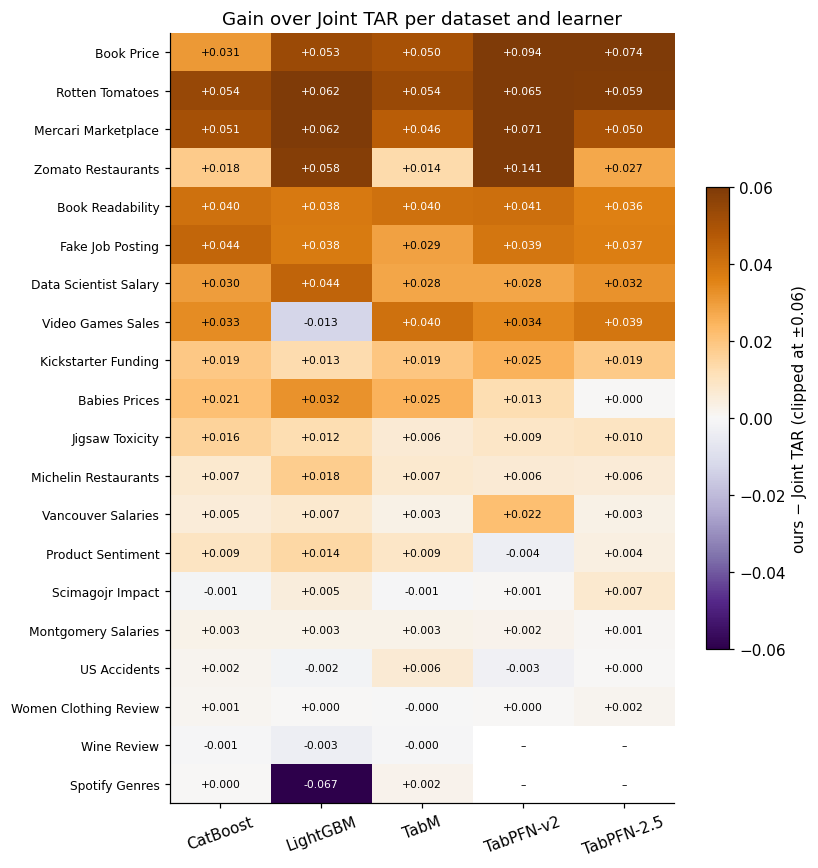

datasets where we win with every learner: 13 of 20
datasets where we lose with every learner: 1 -> ['Wine Review']
datasets won by >= 4 of the learners: 16


In [5]:
piv = per_ds.pivot(index="name", columns="learner", values="gain_vs_tar")[LEARNERS]
piv = piv.loc[piv.mean(axis=1).sort_values(ascending=False).index]
lim = 0.06
fig, ax = plt.subplots(figsize=(7.5, 8))
im = ax.imshow(piv.clip(-lim, lim), cmap="PuOr_r", vmin=-lim, vmax=lim, aspect="auto")
ax.set_xticks(range(len(LEARNERS)), LEARNERS, rotation=20); ax.set_yticks(range(len(piv)), piv.index, fontsize=8)
for i in range(piv.shape[0]):
    for j in range(piv.shape[1]):
        v = piv.iat[i, j]
        ax.text(j, i, "–" if np.isnan(v) else f"{v:+.3f}", ha="center", va="center", fontsize=7,
                color="white" if abs(v) > 0.035 else "black")  # readable on the darkest cells
fig.colorbar(im, ax=ax, shrink=0.6, label="ours − Joint TAR (clipped at ±0.06)")
ax.set_title("Gain over Joint TAR per dataset and learner")
fig.tight_layout(); fig.savefig(join(FIG, "fig2_gain_heatmap.png"), dpi=200); plt.show()
n_pos = (piv > 0).sum(axis=1); n_obs = piv.notna().sum(axis=1)
print("datasets where we win with every learner:", int((n_pos == n_obs).sum()), "of", len(piv))
print("datasets where we lose with every learner:", int((n_pos == 0).sum()), "->", list(piv.index[n_pos == 0]))
print("datasets won by >= 4 of the learners:", int((n_pos >= 4).sum()))

**The one dark cell: LightGBM on Spotify Genres.** It is a single failed run, not a pattern. Fold 3 scores AUROC 0.536
on the Tesla T4 GPU, against 0.906–0.915 on the other four folds and 0.913 when the same job is re-run on an A100;
CatBoost and TabM score 0.963 and 0.962 on the same fold's features. Averaged over the 5 folds, that one run gives the
−0.067. It is kept as measured (section 7b has the per-fold scores and the re-run).

## 4. Consistency: folds, learners and noise

A mean gain can hide a few large wins. Three checks of how regular the gain is:
1. **Folds:** the share of the individual (learner, dataset, fold) runs where we beat Joint TAR.
2. **Learners:** whether the datasets we win agree across learners.
3. **Noise:** each dataset's gain against its own fold-to-fold noise in the leaderboard (`reports/phase0/baseline_noise.csv`,
   the standard deviation of paired fold differences between two baselines).

In [6]:
fl = folds.assign(win=folds.gain_vs_tar > 0)
print("runs won, per learner:", fl.groupby("learner").win.mean().loc[LEARNERS].round(3).to_dict())
print(f"all runs: {fl.win.mean():.3f} of {len(fl)}")
agree = piv.dropna().gt(0)
print("pairwise agreement of win/loss between learners (share of datasets):")
print(pd.DataFrame({a: {b: (agree[a] == agree[b]).mean() for b in LEARNERS} for a in LEARNERS}).round(2))

runs won, per learner: {'CatBoost': 0.81, 'LightGBM': 0.82, 'TabM': 0.83, 'TabPFN-v2': 0.833, 'TabPFN-2.5': 0.867}
all runs: 0.831 of 480
pairwise agreement of win/loss between learners (share of datasets):
            CatBoost  LightGBM  TabM  TabPFN-v2  TabPFN-2.5
CatBoost        1.00      0.83  0.94       0.83        0.94
LightGBM        0.83      1.00  0.78       0.89        0.89
TabM            0.94      0.78  1.00       0.78        0.89
TabPFN-v2       0.83      0.89  0.78       1.00        0.89
TabPFN-2.5      0.94      0.89  0.89       0.89        1.00


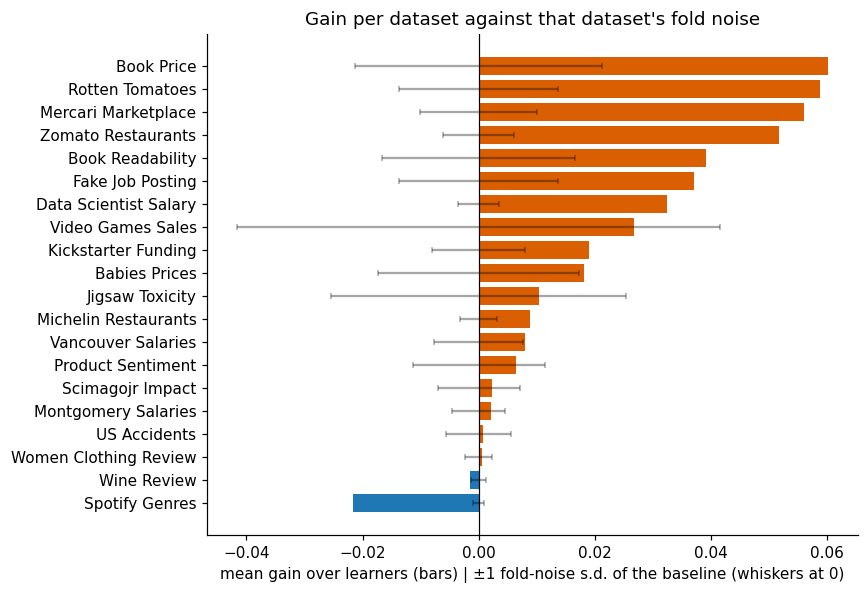

datasets whose mean gain exceeds 1 noise s.d.: 11 of 20
datasets whose mean loss exceeds 1 noise s.d.: 2


,name,mean_gain,paired_diff_std,gain_over_noise
11,Book Price,0.0603,0.0213,2.8307
15,Rotten Tomatoes,0.0588,0.0137,4.2997
13,Mercari Marketplace,0.0560,0.0101,5.5616
19,Zomato Restaurants,0.0517,0.0061,8.5283
12,Book Readability,0.0393,0.0166,2.3635
0,Fake Job Posting,0.0372,0.0137,2.7179
3,Data Scientist Salary,0.0325,0.0035,9.2073
18,Video Games Sales,0.0269,0.0416,0.6449
2,Kickstarter Funding,0.0190,0.0081,2.3466
10,Babies Prices,0.0182,0.0174,1.0462


In [7]:
noise = pd.read_csv(R("reports", "phase0", "baseline_noise.csv"))[["dataset", "paired_diff_std", "mde_paired"]]
g = per_ds.groupby("dataset").gain_vs_tar.mean().rename("mean_gain").reset_index().merge(noise, on="dataset")
g["name"] = g.dataset.map(NAME)
g["gain_over_noise"] = g.mean_gain / g.paired_diff_std
g = g.sort_values("mean_gain")
fig, ax = plt.subplots(figsize=(8, 5.5))
ax.barh(g.name, g.mean_gain, color=[C_OURS if v > 0 else C_TAR for v in g.mean_gain])
ax.errorbar(np.zeros(len(g)), range(len(g)), xerr=g.paired_diff_std, fmt="none", ecolor="k", alpha=0.35, capsize=2)
ax.axvline(0, color="k", lw=0.8)
ax.set_xlabel("mean gain over learners (bars) | ±1 fold-noise s.d. of the baseline (whiskers at 0)")
ax.set_title("Gain per dataset against that dataset's fold noise")
fig.tight_layout(); fig.savefig(join(FIG, "fig3_gain_vs_noise.png"), dpi=200); plt.show()
print("datasets whose mean gain exceeds 1 noise s.d.:", int((g.gain_over_noise > 1).sum()), "of", len(g))
print("datasets whose mean loss exceeds 1 noise s.d.:", int((g.gain_over_noise < -1).sum()))
g[["name", "mean_gain", "paired_diff_std", "gain_over_noise"]].sort_values("mean_gain", ascending=False).round(4)

## 5. Where the gain comes from

**By task type**, and against **how much fine-tuning itself helps** on each dataset (Joint TAR − Joint Frozen on the
leaderboard). Fine-tuning changes the encoder; our method never does. Where the target depends on what a frozen
encoder cannot represent, fine-tuning should keep an edge.

In [8]:
by_task = per_ds.pivot_table(index="task_type", columns="learner", values="gain_vs_tar", aggfunc="mean")[LEARNERS]
by_task["datasets"] = per_ds.groupby("task_type").dataset.nunique()
by_task.round(4)

learner,CatBoost,LightGBM,TabM,TabPFN-v2,TabPFN-2.5,datasets
task_type,,,,,,
binary,0.0261,0.0210,0.0180,0.0242,0.0217,3
multiclass,0.0069,0.0007,0.0074,0.0057,0.0088,7
regression,0.0256,0.0307,0.0274,0.0484,0.0297,10


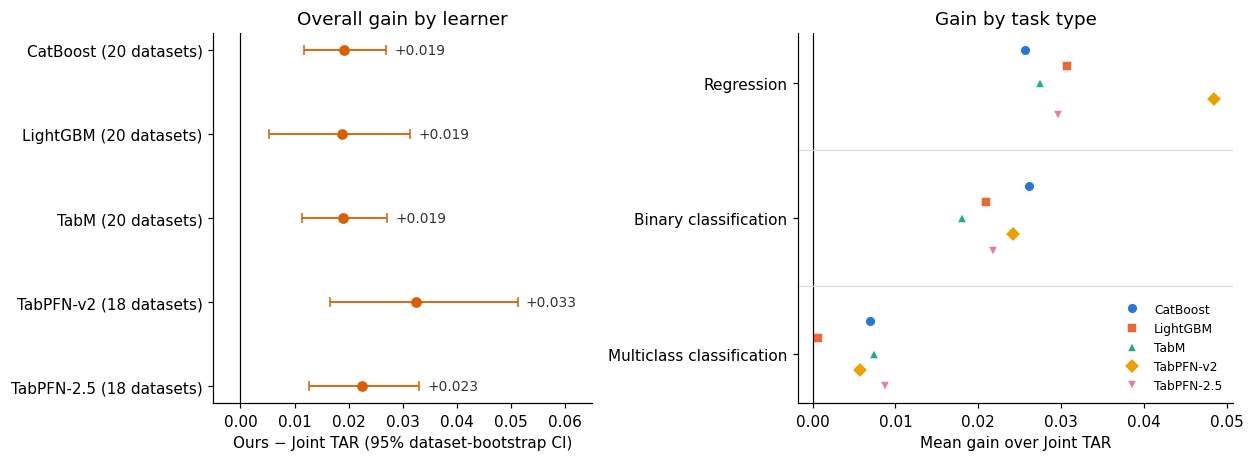

Regression          Binary classification           \
            mean gain datasets             mean gain datasets   
learner                                                         
CatBoost       0.0256       10                0.0261        3   
LightGBM       0.0307       10                0.0210        3   
TabM           0.0274       10                0.0180        3   
TabPFN-v2      0.0484       10                0.0242        3   
TabPFN-2.5     0.0297       10                0.0217        3   

           Multiclass classification           
                           mean gain datasets  
learner                                        
CatBoost                      0.0069        7  
LightGBM                      0.0007        7  
TabM                          0.0074        7  
TabPFN-v2                     0.0057        5  
TabPFN-2.5                    0.0088        5

In [9]:
# Left: overall gain per learner (results/summary.csv); right: mean gain per task type (results/scores_per_dataset.csv,
# already fold-averaged per dataset; unweighted mean over each learner's available datasets in the group).
GROUPS = [("regression", "Regression"), ("binary", "Binary classification"), ("multiclass", "Multiclass classification")]
COLORS = {"CatBoost": "#2a78d6", "LightGBM": "#eb6834", "TabM": "#1baf7a", "TabPFN-v2": "#eda100", "TabPFN-2.5": "#e87ba4"}
MARKERS = {"CatBoost": "o", "LightGBM": "s", "TabM": "^", "TabPFN-v2": "D", "TabPFN-2.5": "v"}
grp = per_ds.groupby(["learner", "task_type"]).gain_vs_tar
grp_mean, grp_n = grp.mean().unstack(), grp.size().unstack()

fig, (axl, axr) = plt.subplots(1, 2, figsize=(11.5, 4.3), gridspec_kw={"width_ratios": [1, 1.15]})
yl = np.arange(len(LEARNERS))
sl = summary.loc[LEARNERS]
axl.errorbar(sl.mean_gain, yl, xerr=[sl.mean_gain - sl.ci95_low, sl.ci95_high - sl.mean_gain], fmt="o", color=C_OURS,
             ms=6, capsize=3, lw=1.2)
for i, l in enumerate(LEARNERS):
    axl.text(sl.ci95_high[l] + 0.0015, i, f"{sl.mean_gain[l]:+.3f}", va="center", fontsize=9, color="#333333")
axl.axvline(0, color="k", lw=0.8)
axl.set_yticks(yl, [f"{l} ({int(sl.datasets[l])} datasets)" for l in LEARNERS]); axl.invert_yaxis()
axl.set_xlim(-0.005, 0.065)
axl.set_xlabel("Ours − Joint TAR (95% dataset-bootstrap CI)")
axl.set_title("Overall gain by learner")

offsets = dict(zip(LEARNERS, np.linspace(-0.24, 0.24, len(LEARNERS))))
for gi, (key, _) in enumerate(GROUPS):
    for l in LEARNERS:
        axr.plot(grp_mean.loc[l, key], gi + offsets[l], MARKERS[l], color=COLORS[l], ms=7, mec="white", mew=1.0,
                 label=l if gi == 0 else None)
axr.axvline(0, color="k", lw=0.8)
axr.set_yticks(range(len(GROUPS)), [lab for _, lab in GROUPS]); axr.invert_yaxis()
for gi in range(len(GROUPS) - 1):
    axr.axhline(gi + 0.5, color="#dddddd", lw=0.8)
axr.set_xlabel("Mean gain over Joint TAR")
axr.set_title("Gain by task type")
axr.legend(fontsize=8, frameon=False, loc="lower right")
fig.tight_layout(); fig.savefig(join(FIG, "fig4a_overall_and_task_gains.png"), dpi=200); plt.show()

tab = pd.concat({lab: pd.DataFrame({"mean gain": grp_mean[key], "datasets": grp_n[key].astype(int)})
                 for key, lab in GROUPS}, axis=1).loc[LEARNERS]
tab.round(4)

*Left: mean paired gain over Joint TAR with 95% bootstrap intervals over datasets. Right: mean gain within each task
type, one point per learner. Classification uses AUROC (macro one-vs-rest for multiclass); regression uses R².*

All five learners have positive overall mean gains, and their 95% dataset-bootstrap intervals lie above zero. Every
learner also has a positive mean gain within each of the three task groups.

Regression shows the largest numerical gains across learners (+0.0256 to +0.0484), followed by binary classification
(+0.0180 to +0.0261) and multiclass classification (+0.0007 to +0.0088; LightGBM's +0.0007 is pulled down by its one
failed Spotify Genres fold, section 7b). These are changes in different metrics—R² and AUROC—so their magnitudes
require separate interpretation.

Positive group averages do not mean improvement on every dataset. Regression improves on 9–10 of 10 datasets per
learner, and binary classification on 3 of 3. Multiclass improvements are less uniform (3–6 datasets per learner). The binary group is
small, and multiclass coverage differs between learners, so this figure describes the observed pattern rather than
establishing a statistically significant difference between task types.

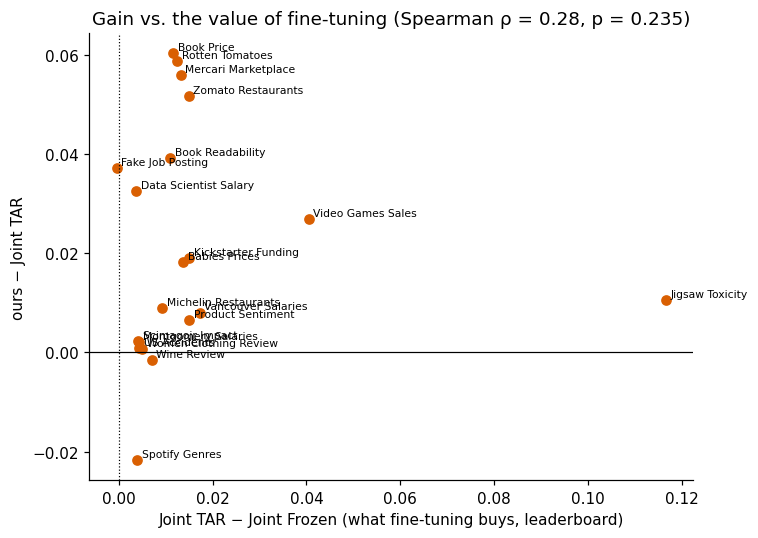

In [10]:
d = per_ds.assign(tar_gain=per_ds.joint_tar - per_ds.joint_frozen).groupby(["dataset", "name"], as_index=False)[
    ["tar_gain", "gain_vs_tar"]].mean()
rho = spearmanr(d.tar_gain, d.gain_vs_tar)
fig, ax = plt.subplots(figsize=(7, 5))
ax.scatter(d.tar_gain, d.gain_vs_tar, color=C_OURS)
for _, r in d.iterrows():
    ax.annotate(r["name"], (r.tar_gain, r.gain_vs_tar), fontsize=7, xytext=(3, 2), textcoords="offset points")
ax.axhline(0, color="k", lw=0.8); ax.axvline(0, color="k", lw=0.8, ls=":")
ax.set_xlabel("Joint TAR − Joint Frozen (what fine-tuning buys, leaderboard)")
ax.set_ylabel("ours − Joint TAR")
ax.set_title(f"Gain vs. the value of fine-tuning (Spearman ρ = {rho.statistic:.2f}, p = {rho.pvalue:.3f})")
fig.tight_layout(); fig.savefig(join(FIG, "fig4_gain_vs_finetuning.png"), dpi=200); plt.show()

## 6. Class imbalance

Two properties of the protocol keep the paired comparison fair under class imbalance: the benchmark's train / test split is
**stratified** by class (tabstar `split_to_test`, `stratify=y`), so every fold keeps the dataset's class ratio, and
**AUROC does not depend on the class ratio** (it measures ranking, not a thresholded accuracy). Both methods are scored
on the same rows. Imbalance can still affect how well either method learns. Below: the class balance of each classification dataset (from the benchmark's own loader) against
our gain.

In [11]:
cb_path = R("results", "class_balance.csv")
if exists(cb_path):
    cb = pd.read_csv(cb_path)
    m = cb.merge(per_ds.groupby("dataset").gain_vs_tar.mean().rename("mean_gain").reset_index(), on="dataset")
    m["name"] = m.dataset.map(NAME)
    display(m[["name", "n_classes", "minority_share", "majority_share", "mean_gain"]].sort_values("minority_share").round(4))
    r = spearmanr(m.minority_share, m.mean_gain)
    print(f"Spearman(minority share, mean gain) = {r.statistic:.2f} (p = {r.pvalue:.2f}, n = {len(m)})")
else:
    print("results/class_balance.csv not found (scripts/class_balance.py builds it; needs the datasets locally)")

,name,n_classes,minority_share,majority_share,mean_gain
8,Wine Review,30,0.0080,0.1262,-0.0015
4,Michelin Restaurants,5,0.0083,0.6138,0.0089
7,US Accidents,4,0.0087,0.7967,0.0008
6,Spotify Genres,114,0.0088,0.0088,-0.0217
5,Product Sentiment,4,0.0191,0.5926,0.0065
9,Women Clothing Review,5,0.0366,0.5555,0.0007
0,Fake Job Posting,2,0.0433,0.9567,0.0372
1,Jigsaw Toxicity,2,0.0604,0.9396,0.0105
3,Data Scientist Salary,6,0.0786,0.2278,0.0325
2,Kickstarter Funding,2,0.3196,0.6804,0.0190


Spearman(minority share, mean gain) = 0.70 (p = 0.03, n = 10)


## 7. What each part contributes

**Build-up** (CatBoost, all 20 datasets, 5 folds, each vs. Joint TAR of the same fold): each expert alone, the lexical
expert *without* cross-fitting, the experts together, then the probe, the depth probes and the attention probe added. All rows are full
benchmark runs (`reports/tables/fold_scores.csv`). **Depth profile**: for all 20 datasets, how well a cross-fitted
linear probe on each of e5's 12 layers predicts the target, minus the final-layer probe (out-of-fold scores on the
training rows of the final CatBoost run, averaged over the 5 folds; `scripts/depth_figures.py`). The dot marks each
dataset's best layer. Colours are clipped at ±0.03 (Book Readability exceeds the scale: +0.055 at layer 3).

,stage,datasets,mean_gain_vs_tar,wins,wilcoxon_p
0,Joint Frozen (leaderboard),20,-0.0204,0,0.0000
1,our Joint TAR re-implementation,20,-0.0017,6,0.0532
2,numeracy features only,20,-0.0108,3,0.0073
3,neighbour expert only,20,-0.0064,5,0.0826
4,"lexical expert, NOT cross-fitted",20,-0.0345,1,0.0001
5,lexical expert only,20,-0.0000,8,0.7285
6,all experts (CTE),20,0.0106,11,0.0583
7,+ probe on the full embedding,20,0.0141,15,0.0023
8,+ depth probes,20,0.0161,14,0.0023
9,+ attention probe = final method,20,0.0191,18,0.0000


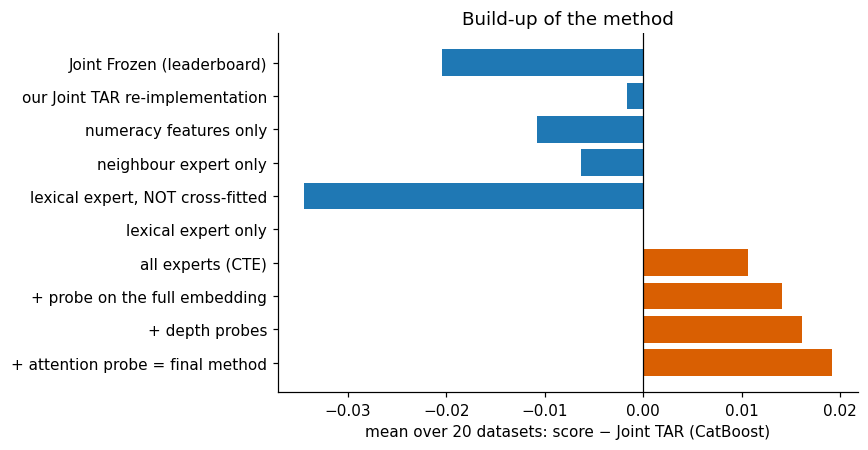

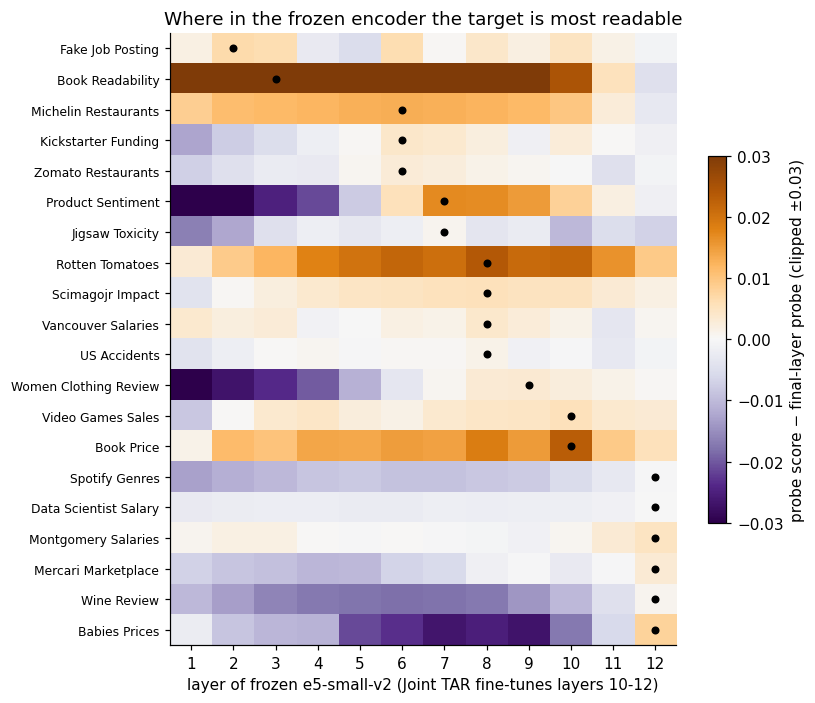

best layer per dataset: {2: 1, 3: 1, 6: 3, 7: 2, 8: 4, 9: 1, 10: 2, 12: 6}
datasets whose best layer is an inner one (< 12): 14 of 20
largest inner-layer gains: {'Book Readability': 0.0545, 'Rotten Tomatoes': 0.0239, 'Book Price': 0.0232, 'Product Sentiment': 0.0171}


In [12]:
fs = pd.read_csv(R("reports", "tables", "fold_scores.csv"))
STAGES = [("Joint Frozen (leaderboard)", None), ("our Joint TAR re-implementation", "tar_repro"),
          ("numeracy features only", "cte_num"), ("neighbour expert only", "cte_nbr"),
          ("lexical expert, NOT cross-fitted", "cte_lex_insample"), ("lexical expert only", "cte_lex"),
          ("all experts (CTE)", "cte"), ("+ probe on the full embedding", "cte_probe"),
          ("+ depth probes", "cte_depth_top3"), ("+ attention probe = final method", "cte_depth_top3_attn")]
cb = fs[(fs.learner == "catboost") & fs.dataset.isin(per_ds.dataset.unique())]
rows = []
for label, m in STAGES:
    d_ = cb[cb.method == "cte"] if m is None else cb[cb.method == m]
    diff = (d_.lb_joint_frozen if m is None else d_.score) - d_.lb_joint_tar
    by = diff.groupby(d_.dataset).mean()
    rows.append({"stage": label, "datasets": by.size, "mean_gain_vs_tar": by.mean(), "wins": int((by > 0).sum()),
                 "wilcoxon_p": wilcoxon(by).pvalue})
bu = pd.DataFrame(rows)
display(bu.round(4))
fig, ax = plt.subplots(figsize=(8, 4.2))
ax.barh(bu.stage, bu.mean_gain_vs_tar, color=[C_OURS if v > 0 else C_TAR for v in bu.mean_gain_vs_tar])
ax.axvline(0, color="k", lw=0.8); ax.invert_yaxis()
ax.set_xlabel("mean over 20 datasets: score − Joint TAR (CatBoost)"); ax.set_title("Build-up of the method")
fig.tight_layout(); fig.savefig(join(FIG, "fig5a_build_up.png"), dpi=200); plt.show()
dp = pd.read_csv(R("reports", "figures", "fig7_depth_profile_20.csv"))
hm = dp.pivot(index="dataset", columns="layer", values="delta")
best = hm.idxmax(axis=1)
hm = hm.loc[best.sort_values().index]
fig, ax = plt.subplots(figsize=(7.5, 6.5))
lim = 0.03
im = ax.imshow(hm.clip(-lim, lim), cmap="PuOr_r", vmin=-lim, vmax=lim, aspect="auto")
ax.scatter(hm.idxmax(axis=1).to_numpy() - 1, range(len(hm)), s=18, color="k")
ax.set_xticks(range(12), range(1, 13)); ax.set_yticks(range(len(hm)), [NAME(d) for d in hm.index], fontsize=8)
ax.set_xlabel("layer of frozen e5-small-v2 (Joint TAR fine-tunes layers 10-12)")
fig.colorbar(im, ax=ax, shrink=0.6, label="probe score − final-layer probe (clipped ±0.03)")
ax.set_title("Where in the frozen encoder the target is most readable")
fig.tight_layout(); fig.savefig(join(FIG, "fig5_depth_profile.png"), dpi=200); plt.show()
print("best layer per dataset:", best.value_counts().sort_index().to_dict())
print("datasets whose best layer is an inner one (< 12):", int((best < 12).sum()), "of", len(best))
print("largest inner-layer gains:", hm.max(axis=1).sort_values(ascending=False).head(4).round(4).rename(index=NAME).to_dict())

## 7b. The attention probe on its own

The final method is the depth-probe version plus one expert, a cross-fitted attention probe on the frozen token states
(`reports/p18/`, specified before its run). Below: the paired difference between the two versions per learner (same
datasets, folds and cross-fitting folds), the one dataset where Joint TAR used to win with every learner (Jigsaw
Toxicity), and LightGBM on Spotify Genres, the one case where the new version is clearly worse.

In [13]:
inc = pd.DataFrame({l: p18["vs_current_method"][SHORT[l]] for l in LEARNERS}).T
display(inc[["n", "mean_diff", "median_diff", "wins", "p_value"]].rename(
    columns={"mean_diff": "mean: final - depth-probe version", "median_diff": "median", "wins": "datasets better"}).round(4))
fs_ = pd.read_csv(R("reports", "tables", "fold_scores.csv"))
fs_ = fs_[fs_.learner.isin(SHORT.values())]
jig = fs_[fs_.dataset == "BIN_TEXT_JIGSAW_TOXICITY"]
jg = pd.DataFrame({lab: (jig[jig.method == m].score - jig[jig.method == m].lb_joint_tar).groupby(jig.learner).mean()
                   for lab, m in (("depth-probe version", "cte_depth_top3"), ("final method", "cte_depth_top3_attn"))})
print("Jigsaw Toxicity, gain over Joint TAR per learner:")
display(jg.round(4))
sp = fs_[(fs_.dataset == "MUL_TEXT_SPOTIFY_GENRES") & fs_.method.isin(["cte_depth_top3", "cte_depth_top3_attn"])]
print("Spotify Genres, score per fold (AUROC):")
display(sp.pivot_table(index=["method", "learner"], columns="fold", values="score").round(3))

,n,mean: final - depth-probe version,median,datasets better,p_value
CatBoost,20,0.003,0.0024,16,0.0064
LightGBM,20,-0.0006,0.0005,13,0.1327
TabM,20,0.0029,0.0021,15,0.0056
TabPFN-v2,18,0.0031,0.001,15,0.0019
TabPFN-2.5,18,0.0021,0.0006,12,0.009


Jigsaw Toxicity, gain over Joint TAR per learner:


,depth-probe version,final method
learner,,
catboost,-0.0078,0.0157
lgbm,-0.0129,0.0124
tabm,-0.0121,0.0061
tabpfnv2,-0.0125,0.0085
tabpfnv2p5,-0.0111,0.0097


Spotify Genres, score per fold (AUROC):


fold                              0      1      2      3      4
method              learner                                    
cte_depth_top3      catboost  0.966  0.961  0.964  0.963  0.964
                    lgbm      0.906  0.907  0.905  0.912  0.914
                    tabm      0.964  0.961  0.964  0.964  0.965
cte_depth_top3_attn catboost  0.966  0.961  0.965  0.963  0.965
                    lgbm      0.909  0.906  0.908  0.536  0.915
                    tabm      0.965  0.964  0.964  0.962  0.967

**Reading.** The attention probe improves four of the five learners by +0.002 to +0.003 on average (p < 0.01 each)
and turns Jigsaw Toxicity from a loss into a win with every learner. LightGBM is the exception (−0.0006 on average,
not significant), and that comes from a single run: on Spotify Genres fold 3, LightGBM scores 0.536 against 0.906–0.915
on the other folds. The features of that fold are sound: CatBoost and TabM score 0.963 and 0.962 on exactly the same
features. LightGBM, run with the benchmark's default settings (100 trees, no early stopping), fails on that fold. We
report the result as measured. Re-run on an A100 GPU instead of the Tesla T4, the same job scores 0.9135 (table
below).

In [14]:
import glob
rows = []
for p in glob.glob(R("results", "raw", "cte_depth_top3_attn", "*", "*", "fold[0-4].json")):
    r = json.load(open(p)); a = r["stacking"]["depth"]["attn"]
    if a["seconds"] > 0:  # the first job of each (dataset, fold) trains the probe; later learners reuse it
        rows.append({"gpu": r["gpu"], "dataset": r["dataset"], "fold": r["fold"], "seconds": a["seconds"]})
at = pd.DataFrame(rows)
t4 = at[at.gpu == "Tesla T4"]
print(f"attention probe training per (dataset, fold) on a Tesla T4: median {t4.seconds.median() / 60:.1f} min, "
      f"max {t4.seconds.max() / 60:.1f} min ({len(t4)} of 100)")

attention probe training per (dataset, fold) on a Tesla T4: median 2.8 min, max 26.5 min (100 of 100)


**Same code, other machine.** 19 of the Tesla T4 jobs were re-run on an A100 machine from the published code
(`reports/p18/a100_check.csv`): the 18 fold-0 jobs differ by +0.0005 on average but up to ±0.02, most on Video Games
Sales, the noisiest dataset, and 5 of them by more than the 0.005 tolerance fixed for this check; LightGBM's failed
Spotify Genres fold does not recur. The machines differ in GPU type, drivers and CPU threads; hardware-dependent
arithmetic in the attention probe's GPU training is a plausible cause. CatBoost, LightGBM and TabM ran on the T4 and TabPFN on the A100, so each learner's comparisons use one GPU type.

In [15]:
chk = pd.read_csv(R("reports", "p18", "a100_check.csv"))
chk["dataset"] = chk.dataset.map(NAME)
f0 = chk[chk.fold == 0].diff_a100_minus_t4
print(f"fold-0 jobs: {len(f0)}, mean A100 - T4 {f0.mean():+.4f}, max |diff| {f0.abs().max():.4f}")
chk.drop(columns=["commit_a100", "dirty_a100"]).round(4)

fold-0 jobs: 18, mean A100 - T4 +0.0005, max |diff| 0.0208


,learner,dataset,fold,score_t4,score_a100,diff_a100_minus_t4
0,catboost,Jigsaw Toxicity,0,0.9163,0.9137,-0.0026
1,catboost,Product Sentiment,0,0.8945,0.8954,0.0009
2,catboost,Women Clothing Review,0,0.9126,0.9121,-0.0005
3,catboost,Babies Prices,0,0.9129,0.9077,-0.0052
4,catboost,Book Price,0,0.6209,0.6212,0.0003
5,catboost,Video Games Sales,0,0.5534,0.5743,0.0208
6,lgbm,Jigsaw Toxicity,0,0.9127,0.9151,0.0024
7,lgbm,Product Sentiment,0,0.8893,0.8921,0.0027
8,lgbm,Spotify Genres,3,0.5357,0.9135,0.3777
9,lgbm,Women Clothing Review,0,0.9046,0.9045,-0.0001


## 8. Cost of building the text features

Joint TAR fine-tunes e5 on a GPU. The depth-probe version builds its features on the CPU; the final method adds the
attention probe, which trains on a GPU (section 7b: median 2.8 min per (dataset, fold) on a Tesla T4). Below, both
timed on the same Colab A100 machine, per (dataset, fold) (`scripts/compute_cost.py`): Joint TAR's time is our fast
re-implementation of its fine-tuning, about 11× faster per epoch than upstream's own code; ours is the depth-probe
version, every expert and probe built from scratch.

In [16]:
cc = pd.read_csv(R("results", "compute_cost.csv"))
ct = cc.groupby("dataset")[["tar_seconds", "ours_seconds"]].mean().div(60).rename(
    columns={"tar_seconds": "Joint TAR fine-tuning, GPU (min)", "ours_seconds": "ours, CPU (min)"})
ct.index = ct.index.map(NAME)
display(ct.sort_values("ours, CPU (min)").round(2))
print(f"median per job: Joint TAR {cc.tar_seconds.median() / 60:.1f} min (GPU), ours {cc.ours_seconds.median() / 60:.1f} min (CPU)")

,"Joint TAR fine-tuning, GPU (min)","ours, CPU (min)"
dataset,,
Product Sentiment,0.27,0.33
Babies Prices,1.28,1.12
Video Games Sales,0.79,1.18
Vancouver Salaries,0.57,1.26
Book Price,1.28,1.53
Book Readability,1.73,1.60
Women Clothing Review,0.71,1.61
Jigsaw Toxicity,0.63,2.07
Montgomery Salaries,1.11,2.07


median per job: Joint TAR 1.3 min (GPU), ours 2.7 min (CPU)


**Reading.** Our method is not faster than an optimised fine-tuning. The depth-probe version takes about 2× its time
per job, on a CPU; the final method adds about 2.8 GPU-minutes for the attention probe, so it costs roughly 4× an
optimised Joint TAR fine-tuning. Both build features once per (dataset, fold) for all learners that share the same
training rows, whereas upstream's Joint TAR fine-tunes again inside every learner's run.

## 9. Beyond the 20: 36 further text datasets

To check that the method was not tuned to the 20 benchmark datasets, the depth-probe version was run once (CatBoost,
folds 0–2; the attention probe came later and was not run here) on 36
further text datasets that have MulTaBench baselines (`multabench/leaderboard/results/text_source/`) and were never
used during development. The **median** is the summary to read: on two used-car price datasets with heavy-tailed
targets (Mercedes-Benz Italy, CarDekho) both methods score R² far below zero on some folds, and the difference of two
broken scores (+11.96 on Mercedes-Benz) dominates the mean.

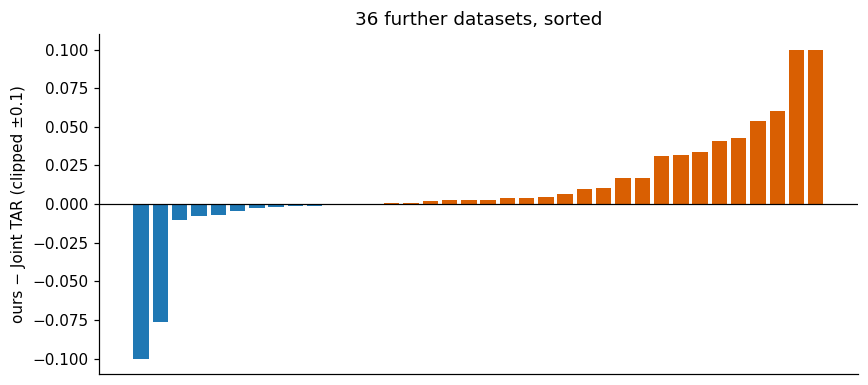

n = 36, wins = 24, median +0.0027, Wilcoxon p = 0.0168, Holm (24) = 0.138
mean +0.3451; without the two heavy-tailed car-price datasets +0.0032


In [17]:
c7 = json.load(open(R("reports", "p14", "p14_report.json")))["C7"]["cte_depth_top3|vs_joint_tar"]
h = pd.Series(c7["per_dataset"]).sort_values()
fig, ax = plt.subplots(figsize=(8, 3.6))
ax.bar(range(len(h)), h.clip(-0.1, 0.1), color=[C_OURS if v > 0 else C_TAR for v in h])
ax.axhline(0, color="k", lw=0.8); ax.set_xticks([])
ax.set_ylabel("ours − Joint TAR (clipped ±0.1)"); ax.set_title("36 further datasets, sorted")
fig.tight_layout(); fig.savefig(join(FIG, "fig6_36_datasets.png"), dpi=200); plt.show()
holm7 = json.load(open(R("reports", "p18", "p18_report.json")))["holm_all_preregistered"]["C7:cte_depth_top3|vs_joint_tar"]
print(f"n = {c7['n']}, wins = {c7['wins']}, median {c7['median_diff']:+.4f}, Wilcoxon p = {c7['p_value']:.4f}, "
      f"Holm (24) = {holm7:.3f}")
heavy = ["REG_TEXT_TRANSPORTATION_USED_CAR_MERCEDES_BENZ_ITALY", "REG_TEXT_CONSUMER_CAR_PRICE_CARDEKHO"]
print(f"mean {c7['mean_diff']:+.4f}; without the two heavy-tailed car-price datasets {h.drop(heavy).mean():+.4f}")

## 10. Trust checks

- **Label shuffle.** The whole method retrained with the training labels randomly permuted (true test labels kept,
  development split of training rows). Label shuffling is a negative control that can expose some leakage paths.
  Performance falls to chance in these checks, for the depth-probe version (first table) and for the final method (second table; on
  the same five Jigsaw permutations both versions spread over 0.47–0.57).
- **Independent recomputation.** `scripts/check_recompute.py` recomputes every headline number from the raw result
  files and the leaderboard CSVs with no project code; it reproduces all 5 rows of section 2.
- **Same benchmark.** Upstream code at tag `paper_version`, unmodified; for these 20 datasets its splits, metrics,
  preprocessing and baseline scores are identical to upstream `master` of 26 July 2026.
- **Same environment.** Our own re-implementation of Joint TAR, run in our environment, scores 0.0017 below the
  published numbers (6 of 20 datasets higher, p = 0.053; section 7). If our environment differs from the authors' at
  all, it lowers scores, which makes the comparison with the published baselines harder for our method, not easier.

In [18]:
display(pd.read_csv(R("reports", "checks", "label_shuffle.csv")).round(4))
display(pd.concat([pd.read_csv(R("reports", "dev", "e52", f)) for f in ("label_shuffle.csv", "label_shuffle_jigsaw.csv")])
        .round(4).reset_index(drop=True))

,dataset,method,train_labels,perm_seed,score,seconds
0,BIN_TEXT_KICKSTARTER_FUNDING,cte_depth_top3,true,NaN,0.7634,362.1
1,BIN_TEXT_KICKSTARTER_FUNDING,cte_depth_top3,shuffled,NaN,0.5326,319.6
2,MUL_TEXT_PRODUCT_SENTIMENT,cte_depth_top3,true,NaN,0.9065,16.2
3,MUL_TEXT_PRODUCT_SENTIMENT,cte_depth_top3,shuffled,NaN,0.4857,13.1
4,REG_TEXT_BOOK_PRICE,cte_depth_top3,true,NaN,0.5640,75.9
5,REG_TEXT_BOOK_PRICE,cte_depth_top3,shuffled,NaN,-0.0081,92.9
6,BIN_TEXT_KICKSTARTER_FUNDING,cte_depth_top3,shuffled,1.0,0.5066,279.9
7,BIN_TEXT_KICKSTARTER_FUNDING,cte_depth_top3,shuffled,2.0,0.5218,415.0
8,BIN_TEXT_KICKSTARTER_FUNDING,cte_depth_top3,shuffled,3.0,0.5001,305.2


,dataset,method,train_labels,perm_seed,score,seconds
0,BIN_TEXT_JIGSAW_TOXICITY,cte_depth_top3_attn,true,NaN,0.9430,207.9
1,BIN_TEXT_JIGSAW_TOXICITY,cte_depth_top3_attn,shuffled,1.0,0.5735,163.4
2,BIN_TEXT_JIGSAW_TOXICITY,cte_depth_top3_attn,shuffled,2.0,0.4882,156.1
3,REG_TEXT_VIDEO_GAMES_SALES,cte_depth_top3_attn,true,NaN,0.4342,84.3
4,REG_TEXT_VIDEO_GAMES_SALES,cte_depth_top3_attn,shuffled,1.0,0.0060,51.8
5,REG_TEXT_VIDEO_GAMES_SALES,cte_depth_top3_attn,shuffled,2.0,-0.0011,55.8
6,MUL_TEXT_PRODUCT_SENTIMENT,cte_depth_top3_attn,true,NaN,0.9118,46.0
7,MUL_TEXT_PRODUCT_SENTIMENT,cte_depth_top3_attn,shuffled,1.0,0.4588,24.5
8,MUL_TEXT_PRODUCT_SENTIMENT,cte_depth_top3_attn,shuffled,2.0,0.4504,23.9
9,BIN_TEXT_JIGSAW_TOXICITY,cte_depth_top3,true,NaN,0.9087,6.3


**Not a lucky seed.** The method's own randomness is the assignment of training rows to the 5 cross-fitting folds
(seed 42 everywhere above; the learners' seeds are fixed by the benchmark). The depth-probe version with LightGBM was
re-run with fold seeds 43 and 44 (`reports/p17/`, specified before the run, Holm over the two seeds). Below: the gain
per seed, then per dataset.

In [19]:
p17 = json.load(open(R("reports", "p17", "p17_report.json")))
runs = {"seed 42": p17["seed42_C10"], "seed 43": p17["C12"]["seed43"], "seed 44": p17["C12"]["seed44"]}
display(pd.DataFrame({k: {"mean gain": c["mean_diff"], "median gain": c["median_diff"], "wins": c["wins"], "p": c["p_value"],
                          "Holm (2 seeds)": c.get("p_holm")} for k, c in runs.items()}).T.round(4))
sd = pd.DataFrame({k: c["per_dataset"] for k, c in runs.items()})
sd.index = sd.index.map(NAME)
sd["sd over seeds"] = sd.std(axis=1, ddof=1)
print(f"per-dataset sd of the gain over the 3 seeds: median {sd['sd over seeds'].median():.4f}, "
      f"max {sd['sd over seeds'].max():.4f} ({sd['sd over seeds'].idxmax()})")
sd.sort_values("sd over seeds", ascending=False).head(5).round(4)

,mean gain,median gain,wins,p,Holm (2 seeds)
seed 42,0.0193,0.0137,14.0,0.0056,NaN
seed 43,0.0169,0.0140,15.0,0.0094,0.0189
seed 44,0.0176,0.0129,15.0,0.0107,0.0189


per-dataset sd of the gain over the 3 seeds: median 0.0013, max 0.0182 (Video Games Sales)


,seed 42,seed 43,seed 44,sd over seeds
Video Games Sales,-0.0240,-0.0583,-0.0517,0.0182
Book Price,0.0535,0.0446,0.0448,0.0051
Babies Prices,0.0231,0.0262,0.0327,0.0049
Vancouver Salaries,0.0086,0.0038,0.0029,0.0031
Book Readability,0.0320,0.0298,0.0336,0.0019


## 11. Summary

1. **Better than Joint TAR with every learner.** The mean gain is +0.019 to +0.033 (AUROC / R²). Measured from Joint
   Frozen, our method adds 1.8× (LightGBM) to 3.4× (TabPFN-2.5) what fine-tuning adds, without fine-tuning.
2. **Significant for all 5 learners** (two-sided Wilcoxon over datasets, p ≤ 0.0073); **4 of 5 also survive** the
   Holm correction over the 24 pre-registered comparisons (LightGBM: 0.095); all 5 survive it over the five final
   comparisons.
3. **Broad, not driven by a few datasets.** 83% of the 480 individual runs beat Joint TAR; 13 of the 20 datasets are
   won with every learner and 16 with at least 4; the learners agree on win / loss for 78–94% of the datasets.
4. **Above the noise.** On 11 of the 20 datasets the mean gain exceeds one standard deviation of the baseline's own
   fold-to-fold noise; two lose by more than that: Wine Review (by 0.0015) and Spotify Genres (by 0.022, from
   LightGBM's one failed fold).
5. **Largest on regression** (+0.026 to +0.048), then binary (+0.018 to +0.026), smallest on multiclass (+0.001 to
   +0.009).
6. **The target sits at different depths**: the best probe layer ranges from 2 to 12 and is an inner layer in 14 of
   the 20 datasets (largest gain: Book Readability, layer 3), which is what the depth probes exploit.
7. **The attention probe** adds +0.002 to +0.003 for four learners (p < 0.01 each) and turns Jigsaw Toxicity, where
   Joint TAR used to win with every learner (by 0.008–0.013), into a win with every learner (+0.006 to +0.016). With
   LightGBM it is −0.0006 on average, all from one failed fold (Spotify Genres fold 3: 0.536). Across datasets the gain
   is not significantly related to how much fine-tuning helps (Spearman ρ = 0.28, p = 0.23).
8. **Class imbalance**: stratified splits and a class-ratio-free metric (AUROC) keep the paired comparison fair, though
   imbalance can still affect how well either method learns. The gain is smaller on the datasets with the rarest classes (ρ = 0.70 with the rarest class's share,
   p = 0.03, 10 datasets): these are the multiclass tasks with 4 to 114 classes, the task type with the smallest gains
   (section 5).
9. **Cross-fitting is essential**: the same lexical expert without it scores 0.034 lower (−0.034 vs. Joint TAR
   instead of ±0.000), and 0.045 below the full set of cross-fitted experts.
10. **On 36 further datasets** (depth-probe version) the gain is positive but small (median +0.003, 24 of 36 won);
   significant on its own (p = 0.017), not after the 24-test correction.
11. **Cost** (section 8): the depth-probe version builds its features in about 2.7 min per job on a CPU, the attention
    probe adds a median 2.8 min on a GPU (T4); an optimised GPU fine-tuning of Joint TAR takes 1.3 min.
12. **No leakage detected in these checks**: with shuffled training labels the final method falls to chance (AUROC 0.45–0.57,
    R² ≤ 0.01), with the same spread as the depth-probe version on the same permutations.
13. **Not a lucky seed** (depth-probe version): with two other cross-fitting fold seeds (LightGBM) the gain is +0.017
    and +0.018 (15 of 20 datasets each, Holm p = 0.019); per dataset it moves by a median 0.001 between seeds, most on
    Video Games Sales.